# Import packages for data handling #

In [3]:
import numpy as np
import pandas as pd
import emcee
from io import StringIO
CO, H2O, CO2, H2, CH2 = range(5)

# Import summarized raw data #

In [4]:
raw_txt = """Experiment block\tTemp\tCO2 mL/min\tCO mL/min\tAr mL/min\tCO/Ar mL/min\tH2 mL/min\tTotal  mL/min\talpha\tPCO\tPCO2\tPH2
H2COVar\t513\t0\t56.84210526\t6.315789474\t63.15789474\t56.84210526\t120\t0.792973876\t2.368421053\t0\t2.368421053
H2COVar\t513\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.783092833\t1.607142857\t0\t3.214285714
H2COVar\t513\t0\t29.18918919\t3.243243243\t32.43243243\t87.56756757\t120\t0.758648032\t1.216216216\t0\t3.648648649
TempVar(Only CO+H2)\t493.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.828590544\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t513.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.778061766\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t533.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.68652452\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t553.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.570689834\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t573.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.484066337\t1.607142857\t0\t3.214285714
H2CO2Var\t513.15\t30\t0\t0\t0\t90\t120\t0.018953371\t0\t1.25\t3.75
H2CO2Var\t513.15\t40\t0\t0\t0\t80\t120\t0.024583548\t0\t1.666666667\t3.333333333
H2CO2Var\t513.15\t60\t0\t0\t0\t60\t120\t0.037047515\t0\t2.5\t2.5
TempVar(Only CO2+H2)\t493.15\t40\t0\t0\t0\t80\t120\t0.02664535\t0\t1.666666667\t3.333333333
TempVar(Only CO2+H2)\t513.15\t40\t0\t0\t0\t80\t120\t0.023100337\t0\t1.666666667\t3.333333333
TempVar(Only CO2+H2)\t533.15\t40\t0\t0\t0\t80\t120\t0.01438644\t0\t1.666666667\t3.333333333
TempVar(Only CO2+H2)\t553.15\t40\t0\t0\t0\t80\t120\t0.008155606\t0\t1.666666667\t3.333333333
TempVar(Only CO+CO2+H2)\t493.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.536381781\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t513.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.469369407\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t533.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.26899611\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t553.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.241802475\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t573.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.235135057\t0.412844037\t0.825688073\t3.715416667
ConstH2CO2Var\t513.15\t10\t0\t80\t0\t30\t120\t0.017891062\t0\t0.416666667\t1.25
ConstH2CO2Var\t513.15\t15\t0\t75\t0\t30\t120\t0.022537633\t0\t0.625\t1.25
ConstH2CO2Var\t513.15\t30\t0\t60\t0\t30\t120\t0.034930099\t0\t1.25\t1.25
ConstH2COVar\t513.15\t0\t9.999\t80.001\t11.00917431\t30\t120\t0.627018131\t0.416625\t0\t1.25
ConstH2COVar\t513.15\t0\t15.003\t74.997\t16.67\t30\t120\t0.662211446\t0.625125\t0\t1.25
ConstH2COVar\t513.15\t0\t29.997\t60.007\t33.33\t30\t120\t0.728855629\t1.249875\t0\t1.25
ConstCOH2Var\t513.15\t0\t26.1\t32.68\t29\t58\t116.78\t0.685585374\t1.117485871\t0\t2.483301935
ConstCOH2Var\t513.15\t0\t26.1\t61.68\t29\t29\t116.78\t0.730646513\t1.117485871\t0\t1.241650968
ConstCOH2Var\t513.15\t0\t26.1\t32.68\t29\t58\t116.78\t0.721576582\t1.117485871\t0\t2.483301935
"""


# Cleaning Data up #

In [5]:
df_raw = pd.read_csv(StringIO(raw_txt), sep=r"\t", engine="python")
df_raw.columns = [str(c).strip().replace("\u00a0", " ") for c in df_raw.columns]

# drop junk
drop_cols = [c for c in df_raw.columns if c.lower().startswith("column")]
df_raw = df_raw.drop(columns=drop_cols, errors="ignore")
df_raw = df_raw.dropna(axis=1, how="all")

rename_map = {
    "Experiment block": "block",
    "Temp": "T",
    "CO2 mL/min": "CO2",
    "CO mL/min": "CO",
    "Ar mL/min": "Ar",
    "CO/Ar mL/min": "CO_Ar",
    "H2 mL/min": "H2",
    "Total  mL/min": "Total",
    "H2:CO ratio": "H2_CO_ratio",
    "H2:CO2 ratio": "H2_CO2_ratio",
}
df = df_raw.rename(columns=rename_map).copy()

required = [
    "block","T","CO2","CO","Ar","CO_Ar","H2","Total",
    "alpha","PCO","PCO2","PH2"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns after cleaning: {missing}\nColumns found: {list(df.columns)}")

for c in required:
    if c != "block":
        df[c] = pd.to_numeric(df[c], errors="coerce")

df["block"] = df["block"].astype(str).str.strip()
df = df.dropna(subset=["block", "T", "alpha"]).copy()

bad_alpha = df[~df["alpha"].between(0.0, 1.0, inclusive="neither")]
if len(bad_alpha) > 0:
    print("Invalid alpha rows (must be 0<alpha<1):")
    display(bad_alpha[["block","T","alpha","CO2","CO","H2"]])
    raise ValueError("Invalid alpha values present.")


# Defining logit and expit functions #

In [6]:
R = 8.314462618            # J/mol/K
P  =  1e5  # Pa (absolute)
T_ref = 500
eps = 1e-12

def logit(a):
    a = np.clip(np.asarray(a, float), eps, 1.0 - eps)
    return np.log(a / (1.0 - a))

def inv_logit(z):
    z = np.asarray(z, float)
    z = np.clip(z, -1000, 1000)
    return 1.0 / (1.0 + np.exp(-z))

In [ ]:
def alpha_model(theta, T, C_CO, C_CO2, C_H2):
    k0, Ea, a, b, c = theta

    T = np.asarray(T, float)
    C_CO  = np.asarray(C_CO, float)
    C_CO2 = np.asarray(C_CO2, float)
    C_H2  = np.asarray(C_H2, float)

    CO_term  = (C_CO  + eps)**a
    CO2_term = (C_CO2 + eps)**b

    denom = k0 * np.exp(Ea/R*(1/T-1/T_ref)) * (CO_term + CO2_term)
    alpha = (1+(C_H2**c+eps)/(denom))**(-1)
    return np.clip(alpha, eps, 1.0 - eps)

In [8]:
T_arr  = df["T"].to_numpy(float)
C_CO   = df["CO"].to_numpy(float)
C_CO2  = df["CO2"].to_numpy(float)
C_H2   = df["H2"].to_numpy(float)

alpha_obs = df["alpha"].to_numpy(float)
y_obs = logit(alpha_obs)

def log_likelihood(theta):
    log_k0, Ea, a, b, c, log_sigma = theta
    sigma = np.exp(log_sigma)

    alpha_mu = alpha_model([log_k0, Ea, a, b, c], T_arr, C_CO, C_CO2, C_H2)
    mu = logit(alpha_mu)

    resid = y_obs - mu
    return -0.5 * np.sum((resid / sigma)**2 + 2*np.log(sigma) + np.log(2*np.pi))

def log_prior(theta):
    k0, Ea, a, b, c, log_sigma = theta
    lp = 0.0

    # log_k0 ~ N(0, 5^2)
    lp += -0.5 * (k0 / 0.1)**2 - np.log(0.1 * np.sqrt(2*np.pi))

    # Ea ~ N(Ea_lin, (5e4)^2)
    lp += -0.5 * ((Ea - 5000) / 5e4)**2 - np.log(5e4 * np.sqrt(2*np.pi))

    # bounds
    if not (0.0 <= a <= 3.0 and -3.0 <= b <= 3.0 and 0.0 <= c <= 3.0):
        return -np.inf

    # Half-Cauchy(2.5) on sigma via log_sigma (Jacobian included)
    sigma = np.exp(log_sigma)
    if sigma <= 0:
        return -np.inf
    lp += np.log(2/np.pi) - np.log(1 + (sigma/2.5)**2) + log_sigma
    return lp

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta)


In [9]:
rng = np.random.default_rng(42)

theta0 = np.array([
    1.0,   # k0
    50001,         # Ea
    1.0,           # a
    1.0,           # b
    1.0,           # c
    np.log(0.5)    # log_sigma
], dtype=float)

ndim = theta0.size
nwalkers = 4 * ndim

p0 = theta0 + rng.normal(
    scale=[0.1, 5e3, 0.15, 0.15, 0.15, 0.15],
    size=(nwalkers, ndim)
)

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)

print("\n--- Burn-in ---")
state = sampler.run_mcmc(p0, 5000, progress=True)

sampler.reset()
print("\n--- Production ---")
sampler.run_mcmc(state, 15000, progress=True)



--- Burn-in ---


100%|██████████| 5000/5000 [00:08<00:00, 612.93it/s]



--- Production ---


100%|██████████| 15000/15000 [00:23<00:00, 639.30it/s]


State([[ 9.03853287e-02  4.48339994e+04  1.22284646e+00 -1.00629393e-01
   1.72657170e-01 -1.55989267e+00]
 [ 5.93359292e-02  5.17128632e+04  1.19492188e+00 -1.17391260e-01
   4.45023260e-02 -1.52003356e+00]
 [ 1.01038488e-01  4.03064726e+04  1.23955064e+00 -1.13874825e-01
   2.21265530e-01 -1.24588740e+00]
 [ 8.62966746e-02  4.71765644e+04  1.23349557e+00 -9.76340267e-02
   1.40766598e-01 -1.31036113e+00]
 [ 7.02193121e-02  4.11512550e+04  1.19176489e+00 -1.14657788e-01
   1.06138150e-01 -1.16958853e+00]
 [ 1.27040455e-01  4.45778188e+04  1.25157205e+00 -9.51030446e-02
   2.52660186e-01 -1.45494365e+00]
 [ 5.87941506e-02  3.93708958e+04  1.17060518e+00 -1.03423545e-01
   3.81176026e-02 -1.40140640e+00]
 [ 8.07942167e-02  5.11681869e+04  1.27549999e+00 -9.10683105e-02
   1.63881362e-01 -9.87191563e-01]
 [ 5.88806183e-02  4.90456408e+04  1.16364317e+00 -1.13374565e-01
   3.08508268e-02 -1.41241840e+00]
 [ 7.20575005e-02  4.62544135e+04  1.17726963e+00 -1.03497560e-01
   6.63647179e-02 -

In [10]:
flat = sampler.get_chain(discard=0, thin=10, flat=True)
k0_s, Ea_s, a_s, b_s, c_s, log_sigma_s = [flat[:, i] for i in range(flat.shape[1])]
sigma_s = np.exp(log_sigma_s)

def summarize(x):
    x = np.asarray(x, float)
    return np.mean(x), np.std(x), np.percentile(x, [5, 50, 95])

print("\n--- Posterior summaries ---")
names = ["k0", "Ea", "a", "b", "c", "sigma"]
for nm, arr in zip(names, [k0_s, Ea_s, a_s, b_s, c_s, sigma_s]):
    m, sd, q = summarize(arr)
    print(f"{nm:8s}: mean={m:.6g}, sd={sd:.6g}, 95% CrI=({q[0]:.6g}, {q[2]:.6g})")




--- Posterior summaries ---
k0      : mean=0.0821738, sd=0.0315508, 95% CrI=(0.0479502, 0.144185)
Ea      : mean=44057.2, sd=6231.44, 95% CrI=(33925, 54149)
a       : mean=1.2197, sd=0.0598333, 95% CrI=(1.12648, 1.31821)
b       : mean=-0.100239, sd=0.0211186, 95% CrI=(-0.12291, -0.0656992)
c       : mean=0.128634, sd=0.0879689, 95% CrI=(0.0119992, 0.293242)
sigma   : mean=0.284927, sd=0.0441869, 95% CrI=(0.22296, 0.365035)


In [11]:
import numpy as np
import matplotlib.pyplot as plt

# --- Original constants from your code (used as means) ---
k_o_sq_mean = 0.113
dEA_mean = -47554.0     # J/mol
T_ref = 500.0
a_mean = 1.027
b_mean = -0.303
c_mean = 0.038
R = 8.314
P = 5e5

# --- Options for uncertainty sampling ---
n_samps = 2000
rng = np.random.default_rng(12345)

# Choose whether to use real posterior draws (if you have them).
# If True, set `draws` to a dict of arrays, e.g. draws = {'k_o_sq': arr, 'dEA': arr, 'a': arr, 'b': arr, 'c': arr}
use_posterior_draws = False
draws = {}  # replace with your arrays if use_posterior_draws = True

# If not using real draws, choose standard deviations for sampling (relative or absolute)
# You can tune these to match the uncertainty you expect.
rel_std_frac = 0.10   # 10% relative std by default for most params
k_o_sq_std = rel_std_frac * abs(k_o_sq_mean)
dEA_std = 5000.0      # absolute std for activation-like parameter (adjust if needed)
a_std = rel_std_frac * max(1e-6, abs(a_mean))
b_std = rel_std_frac * max(1e-6, abs(b_mean))
c_std = rel_std_frac * max(1e-6, abs(c_mean))

# --- Functions (kept the same equilibrium constant and composition formulas) ---
def equilibrium_constant(T):
    # same form you used
    K_eq = np.exp(-13.148 + 1.077 * np.log(T) + 5.44e-4 * T - 1.125e-7 * T**2 + 5693.5 / T - 49170 / T**2)
    return K_eq

def equilibrium_compositions(K_eq):
    sqrtK = np.sqrt(K_eq)
    molefr_CO  = 1.0 / (2.0 * (1.0 + sqrtK))
    molefr_CO2 = sqrtK / (2.0 * (1.0 + sqrtK))
    molefr_H2  = molefr_CO2.copy()
    return molefr_CO, molefr_CO2, molefr_H2

# --- Temperature ranges and reaction temperatures (same as your first code) ---
T_RWGS = np.array([500, 1000, 1500])
T_FT = np.linspace(400, 600, 100)

# --- Prepare sampling of parameters ---
if use_posterior_draws:
    # validate draws dict keys and lengths
    # expected keys: any subset of 'k_o_sq','dEA','a','b','c'
    # If draws arrays have different lengths we sample from them with replacement.
    available_keys = list(draws.keys())
    if not available_keys:
        raise ValueError("use_posterior_draws=True but draws dict is empty. Provide arrays.")
    # build sampled parameter arrays by random choice
    def sample_from_draws(key, n):
        arr = draws[key]
        idx = rng.integers(0, arr.size, size=n)
        return arr[idx]
    k_o_sq_samps = sample_from_draws('k_o_sq', n_samps) if 'k_o_sq' in draws else rng.normal(k_o_sq_mean, k_o_sq_std, n_samps)
    dEA_samps   = sample_from_draws('dEA', n_samps)     if 'dEA' in draws     else rng.normal(dEA_mean, dEA_std, n_samps)
    a_samps     = sample_from_draws('a', n_samps)       if 'a' in draws       else rng.normal(a_mean, a_std, n_samps)
    b_samps     = sample_from_draws('b', n_samps)       if 'b' in draws       else rng.normal(b_mean, b_std, n_samps)
    c_samps     = sample_from_draws('c', n_samps)       if 'c' in draws       else rng.normal(c_mean, c_std, n_samps)
else:
    # Gaussian approx around the constant values
    k_o_sq_samps = rng.normal(k_o_sq_mean, k_o_sq_std, size=n_samps)
    dEA_samps    = rng.normal(dEA_mean, dEA_std, size=n_samps)
    a_samps      = rng.normal(a_mean, a_std, size=n_samps)
    b_samps      = rng.normal(b_mean, b_std, size=n_samps)
    c_samps      = rng.normal(c_mean, c_std, size=n_samps)

# --- Ensure no non-physical samples (e.g., non-positive k_o_sq) ---
k_o_sq_samps = np.clip(k_o_sq_samps, 1e-8, None)

# --- Vectorized computation of alpha samples for each T_RWGS ---
# Will store median and bands per reaction temperature for plotting
results = []

for T_rxn in T_RWGS:
    # equilibrium at reaction temperature (scalar)
    K_eq = equilibrium_constant(T_rxn)
    molefr_CO, molefr_CO2, molefr_H2 = equilibrium_compositions(K_eq)

    # partial pressures (scalars)
    P_CO  = molefr_CO  * P
    P_CO2 = molefr_CO2 * P
    P_H2  = molefr_H2 * P

    # concentrations across T_FT (shape (n_T,))
    C_CO  = P_CO  / (R * T_FT)
    C_CO2 = P_CO2 / (R * T_FT)
    C_H2  = P_H2  / (R * T_FT)

    # expand to shape (n_samps, n_T) using broadcasting
    C_CO_mat  = C_CO[None, :]   # (1, n_T)
    C_CO2_mat = C_CO2[None, :]
    C_H2_mat  = C_H2[None, :]

    # parameters per sample (n_samps,1) broadcast across temperatures
    a_mat = a_samps[:, None]
    b_mat = b_samps[:, None]
    c_mat = c_samps[:, None]
    k_o_sq_mat = k_o_sq_samps[:, None]
    # Arrhenius-like exponential factor depends on T_FT (vector)
    exp_factor = np.exp((dEA_samps[:, None] / R) * ((1.0 / T_ref) - (1.0 / T_FT[None, :])))  # shape (n_samps, n_T)

    # compute denominator term: k_o_sq * exp_factor * (C_CO**a + C_CO2**b)
    # careful: C_CO**a where a varies per sample: use broadcasted power
    C_CO_pow = np.power(C_CO_mat, a_mat)         # (n_samps, n_T)
    C_CO2_pow = np.power(C_CO2_mat, b_mat)       # (n_samps, n_T)
    denom = k_o_sq_mat * exp_factor * (C_CO_pow + C_CO2_pow)  # (n_samps, n_T)
    numer = np.power(C_H2_mat, c_mat)            # (n_samps, n_T)

    # avoid division by zero - clamp denom upward
    denom = np.clip(denom, 1e-16, None)

    alpha_samps = (1.0 + numer / denom) ** -1.0  # shape (n_samps, n_T)

    # compute median and credible bands across samples for each T
    alpha_med = np.percentile(alpha_samps, 50, axis=0)
    alpha_lo50 = np.percentile(alpha_samps, 25, axis=0)
    alpha_hi50 = np.percentile(alpha_samps, 75, axis=0)
    alpha_lo95 = np.percentile(alpha_samps, 2.5, axis=0)
    alpha_hi95 = np.percentile(alpha_samps, 97.5, axis=0)

    results.append({
        'T_rxn': T_rxn,
        'alpha_med': alpha_med,
        'alpha_lo50': alpha_lo50,
        'alpha_hi50': alpha_hi50,
        'alpha_lo95': alpha_lo95,
        'alpha_hi95': alpha_hi95
    })

for res in results:
    print(f"\nT_RWGS = {res['T_rxn']} K")

    for T, alpha in zip(T_FT, res['alpha_med']):
        print(f"T_FT = {T:.2f} K: alpha = {alpha:.6f}")

results[0]['alpha_med']  # T_RWGS = 500 K
results[1]['alpha_med']  # T_RWGS = 1000 K
results[2]['alpha_med']  # T_RWGS = 1500 K

idx = np.argmin(np.abs(T_FT - 500))

alpha_value = results[0]['alpha_med'][idx]

print(f"alpha = {alpha_value:.6f}")


T_RWGS = 500 K
T_FT = 400.00 K: alpha = 0.913606
T_FT = 402.02 K: alpha = 0.907443
T_FT = 404.04 K: alpha = 0.900971
T_FT = 406.06 K: alpha = 0.894153
T_FT = 408.08 K: alpha = 0.886853
T_FT = 410.10 K: alpha = 0.879214
T_FT = 412.12 K: alpha = 0.871190
T_FT = 414.14 K: alpha = 0.862789
T_FT = 416.16 K: alpha = 0.853882
T_FT = 418.18 K: alpha = 0.844868
T_FT = 420.20 K: alpha = 0.835348
T_FT = 422.22 K: alpha = 0.825762
T_FT = 424.24 K: alpha = 0.815693
T_FT = 426.26 K: alpha = 0.805122
T_FT = 428.28 K: alpha = 0.794114
T_FT = 430.30 K: alpha = 0.782875
T_FT = 432.32 K: alpha = 0.771104
T_FT = 434.34 K: alpha = 0.759279
T_FT = 436.36 K: alpha = 0.747273
T_FT = 438.38 K: alpha = 0.734897
T_FT = 440.40 K: alpha = 0.722113
T_FT = 442.42 K: alpha = 0.708985
T_FT = 444.44 K: alpha = 0.695883
T_FT = 446.46 K: alpha = 0.682493
T_FT = 448.48 K: alpha = 0.669043
T_FT = 450.51 K: alpha = 0.655653
T_FT = 452.53 K: alpha = 0.642069
T_FT = 454.55 K: alpha = 0.628329
T_FT = 456.57 K: alpha = 0.61426

n= 1, w_n=0.03839
n= 2, w_n=0.06174
n= 3, w_n=0.07447
n= 4, w_n=0.07983
n= 5, w_n=0.08024
n= 6, w_n=0.07742
n= 7, w_n=0.07262
n= 8, w_n=0.06674
n= 9, w_n=0.06037
n=10, w_n=0.05393
n=11, w_n=0.04770
n=12, w_n=0.04184
n=13, w_n=0.03645
n=14, w_n=0.03156
n=15, w_n=0.02719
n=16, w_n=0.02332
n=17, w_n=0.01992
n=18, w_n=0.01696
n=19, w_n=0.01439
n=20, w_n=0.01218
n=21, w_n=0.01028
n=22, w_n=0.00866
n=23, w_n=0.00728
n=24, w_n=0.00611
n=25, w_n=0.00512
n=26, w_n=0.00428
n=27, w_n=0.00357
n=28, w_n=0.00298
n=29, w_n=0.00248
n=30, w_n=0.00206
n=31, w_n=0.00171
n=32, w_n=0.00142
n=33, w_n=0.00118
n=34, w_n=0.00098
n=35, w_n=0.00081
n=36, w_n=0.00067
n=37, w_n=0.00055
n=38, w_n=0.00046
n=39, w_n=0.00038
n=40, w_n=0.00031
n=41, w_n=0.00026
n=42, w_n=0.00021
n=43, w_n=0.00017
n=44, w_n=0.00014
n=45, w_n=0.00012
n=46, w_n=0.00010
n=47, w_n=0.00008
n=48, w_n=0.00007
n=49, w_n=0.00005
n=50, w_n=0.00004

Sum (1..50): 0.999802


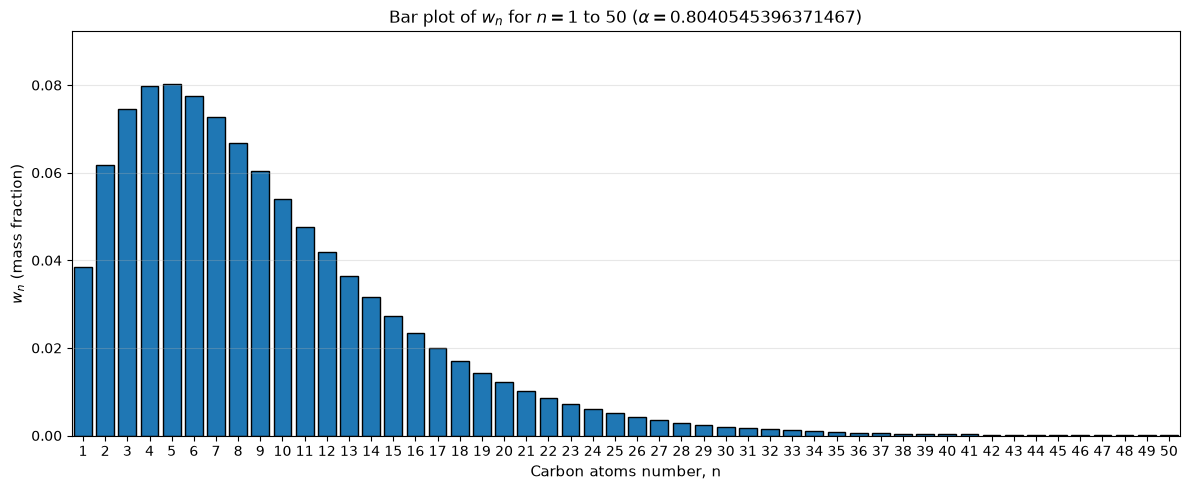

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Carbon atom numbers: n = 1 to 50
n_values = np.arange(1, 51)

# Calculate mass fraction
w_values = n_values * alpha**(n_values - 1) * (1 - alpha)**2
total = w_values.sum()

# Print values and sum
for n, w in zip(n_values, w_values):
    print(f"n={n:2d}, w_n={w:.5f}")

print(f"\nSum (1..50): {total:.6f}")

# Plot bar chart
plt.figure(figsize=(12, 5))

plt.bar(
    n_values,
    w_values,
    color="tab:blue",
    edgecolor="black",
    width=0.8
)

plt.xlabel("Carbon atoms number, n", fontsize=11)
plt.ylabel(r"$w_n$ (mass fraction)", fontsize=11)
plt.title(
    rf"Bar plot of $w_n$ for $n=1$ to $50$ "
    rf"($\alpha={alpha}$)",
    fontsize=12
)

plt.grid(axis="y", alpha=0.3)
plt.xlim(0.5, 50.5)
plt.ylim(0, w_values.max() * 1.15)
plt.xticks(n_values)
plt.tight_layout()
plt.show()

ALPHA VALUES FOR STAGES 1 TO 100
Stage    α (Alpha)           
--------------------------------------------------
1        1.2105930222e-01
2        2.0253726248e-01
3        2.6787833329e-01
4        3.2147003904e-01
5        3.6622678065e-01
6        4.0416821102e-01
7        4.3674021345e-01
8        4.6500588628e-01
9        4.8976466774e-01
10       5.1162945224e-01
11       5.3107808004e-01
12       5.4848863763e-01
13       5.6416422204e-01
14       5.7835066906e-01
15       5.9124947469e-01
16       6.0302736613e-01
17       6.1382349455e-01
18       6.2375491215e-01
19       6.3292079304e-01
20       6.4140572180e-01
21       6.4928228167e-01
22       6.5661311036e-01
23       6.6345254718e-01
24       6.6984796319e-01
25       6.7584084338e-01
26       6.8146767320e-01
27       6.8676066954e-01
28       6.9174838701e-01
29       6.9645622380e-01
30       7.0090684587e-01
31       7.0512054458e-01
32       7.0911553951e-01
33       7.1290823614e-01
34       7.1651344598e-01
35

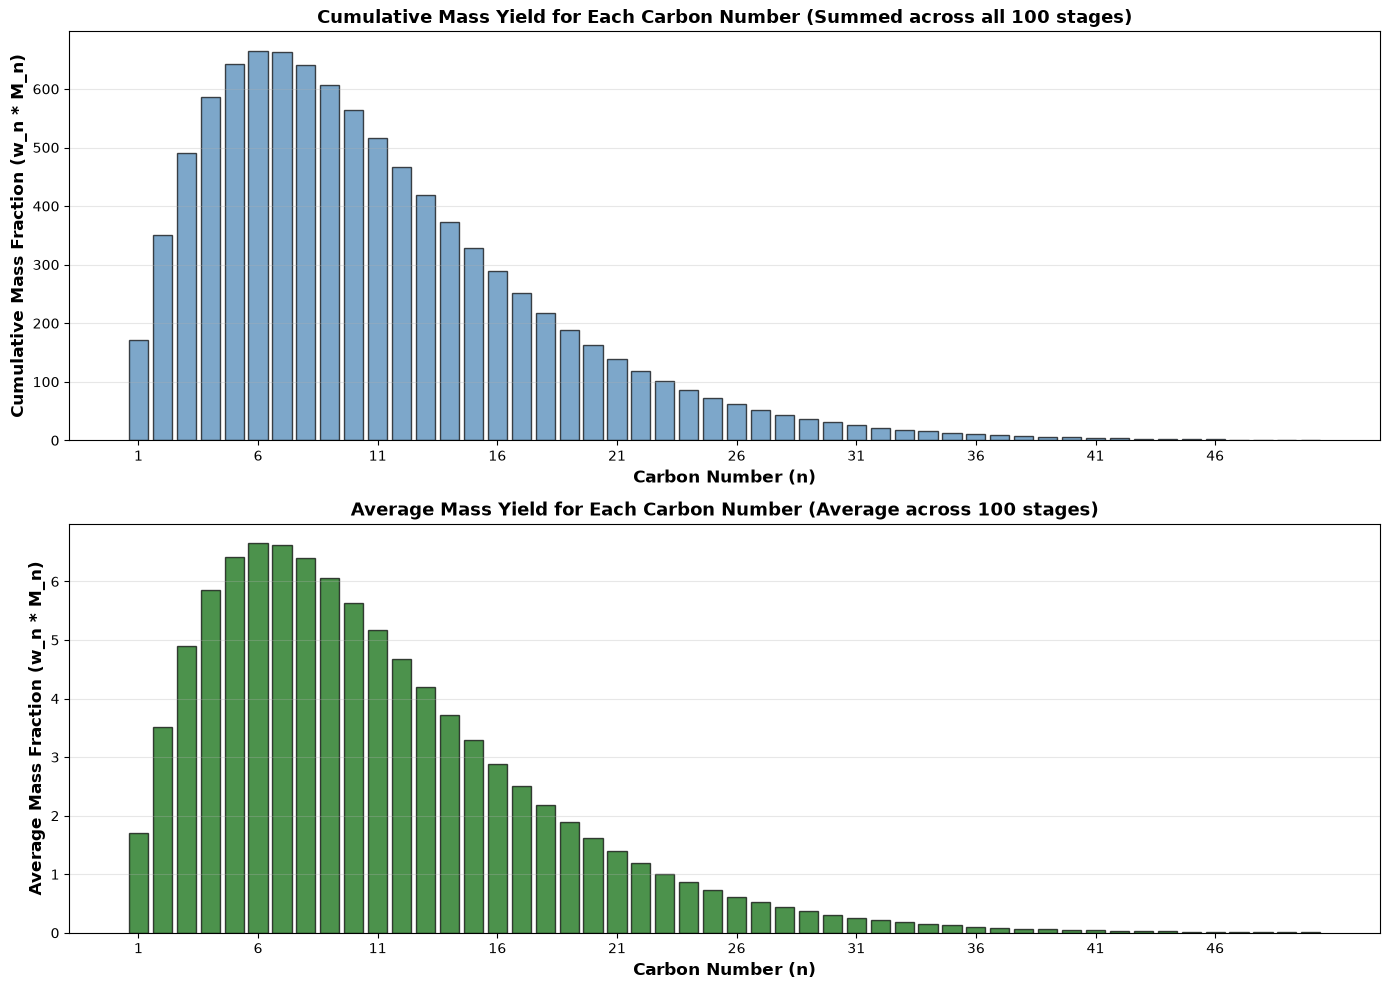


SUMMARY STATISTICS
Total cumulative mass across all carbon numbers and stages: 9.4879657954e+03
Average cumulative mass per carbon number: 1.8975931591e+02
Maximum cumulative mass (at n=6): 6.6511429541e+02
Minimum cumulative mass (at n=50): 7.5236905739e-01


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Constants and inputs ---
R = 8.314            # J/mol/K
T_FT = 473           # K (reactor temperature)
P_CO0 = 1.0e5        # Pa
P_H20 = 2.0e5        # Pa

# Convert inlet pressures -> concentrations (ideal gas)
C_CO0 = P_CO0 / (R * T_FT)
C_H20 = P_H20 / (R * T_FT)

a = -0.75
b = 0.996
N = 100
tau = 35.55          # s

# Arrhenius params
E = 7.64e5           # J/mol
k0 = 5.16e5          # pre-exponential

demo_mode = True
k0_scale = 1.0 if not demo_mode else 1e30

def r_demo(C_CO, C_H2, k_demo=1e-4):
    return k_demo * (C_CO ** 1.0) * (C_H2 ** 0.5)

# --- Stage loop to get concentrations ---
C_CO = np.zeros(N + 1)
C_H2 = np.zeros(N + 1)

C_CO[0] = C_CO0
C_H2[0] = C_H20

for i in range(1, N + 1):
    r_prev = r_demo(C_CO[i-1], C_H2[i-1], k_demo=1e-4)
    delta_CO = tau * r_prev
    delta_H2 = 2.0 * tau * r_prev
    C_CO[i] = max(C_CO[i-1] - delta_CO, 0.0)
    C_H2[i] = max(C_H2[i-1] - delta_H2, 0.0)

# --- Parameters for α calculation ---
k_o_sq = 0.113
dEA = -47554          # J/mol
T_ref = 500
c = 0.038

def calculate_C_CO2(stage, C_CO_inlet, C_CO_stage):
    return C_CO_inlet - C_CO_stage

# --- Calculate α for each stage ---
alpha_list = np.zeros(N + 1)

for i in range(N + 1):
    C_CO_i = C_CO[i]
    C_H2_i = C_H2[i]
    C_CO2_i = calculate_C_CO2(i, C_CO0, C_CO[i])
    
    if C_CO_i <= 0 or C_CO2_i <= 0:
        alpha_list[i] = 0.0
    else:
        numerator = C_H2_i ** c
        denominator_term = k_o_sq * np.exp((dEA / R) * ((1 / T_ref) - (1 / T_FT))) * (C_CO_i ** (-0.75) + C_CO2_i ** 0.996)
        
        if denominator_term <= 0:
            alpha_list[i] = 0.0
        else:
            fraction = numerator / denominator_term
            alpha_list[i] = (1 + fraction) ** (-1)

# --- Molar mass calculation ---
# For hydrocarbon CnH(2n+2): M_n = 12*n + 1*(2n+2) = 12n + 2n + 2 = 14n + 2 (g/mol)
def molar_mass(n):
    """Calculate molar mass of CnH(2n+2) in g/mol"""
    return 14 * n + 2

# --- Print Alpha values for stages 1 to 100 ---
print("="*50)
print("ALPHA VALUES FOR STAGES 1 TO 100")
print("="*50)
print(f"{'Stage':<8} {'α (Alpha)':<20}")
print("-"*50)

for stage in range(1, N + 1):
    print(f"{stage:<8} {alpha_list[stage]:.10e}")

# --- Calculate and print w_n * M_n for each stage (1 to 100) ---
print("\n" + "="*130)
print("MASS YIELD (w_n * M_n) FOR HYDROCARBONS CnH(2n+2) (n = 1 to 50) AT EACH STAGE (1 to 100)")
print("Formula: w_n = n * α^(n-1) * (1 - α)^2")
print("         M_n = 14n + 2 (molar mass in g/mol)")
print("         Product = w_n * M_n")
print("="*130)

# Store total mass for each stage
total_mass_per_stage = np.zeros(N + 1)

for stage in range(1, N + 1):
    alpha = alpha_list[stage]
    print(f"\nStage {stage}: α = {alpha:.10e}")
    print(f"{'n':<6} {'M_n':<12} {'w_n':<22} {'w_n*M_n':<22}")
    print("-"*70)
    
    stage_total_mass = 0.0
    for n in range(1, 51):
        M_n = molar_mass(n)
        w_n = n * (alpha ** (n - 1)) * ((1 - alpha) ** 2)
        product = w_n * M_n
        stage_total_mass += product
        print(f"{n:<6} {M_n:<12} {w_n:<22.10e} {product:<22.10e}")
    
    total_mass_per_stage[stage] = stage_total_mass
    print(f"{'TOTAL MASS FOR STAGE':<50} {stage_total_mass:<22.10e}")

# --- Calculate cumulative mass fraction for each carbon number (summed across all stages) ---
print("\n" + "="*100)
print("CUMULATIVE MASS FRACTION FOR EACH CARBON NUMBER (n = 1 to 50)")
print("Summation of (w_n * M_n) across all stages (1 to 100) for each carbon number")
print("="*100)

cumulative_mass_per_carbon = np.zeros(50)
print(f"{'Carbon Number n':<20} {'Cumulative Mass (w_n*M_n) across all stages':<50}")
print("-"*70)

for n in range(1, 51):
    M_n = molar_mass(n)
    cumulative_mass = 0.0
    for stage in range(1, N + 1):
        alpha = alpha_list[stage]
        w_n = n * (alpha ** (n - 1)) * ((1 - alpha) ** 2)
        product = w_n * M_n
        cumulative_mass += product
    
    cumulative_mass_per_carbon[n - 1] = cumulative_mass
    print(f"{n:<20} {cumulative_mass:<50.10e}")

# --- Calculate average mass fraction (cumulative / number of stages) ---
print("\n" + "="*100)
print("AVERAGE MASS FRACTION FOR EACH CARBON NUMBER (n = 1 to 50)")
print("Average = Cumulative Mass / Number of Stages (100)")
print("="*100)

average_mass_per_carbon = cumulative_mass_per_carbon / N
print(f"{'Carbon Number n':<20} {'Average Mass Fraction':<50}")
print("-"*70)

for n in range(1, 51):
    print(f"{n:<20} {average_mass_per_carbon[n - 1]:<50.10e}")

# --- Plot bar graph ---
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

carbon_numbers = np.arange(1, 51)

# Plot 1: Cumulative mass fraction for each carbon number
axes[0].bar(carbon_numbers, cumulative_mass_per_carbon, color='steelblue', alpha=0.7, edgecolor='black')
axes[0].set_xlabel('Carbon Number (n)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Cumulative Mass Fraction (w_n * M_n)', fontsize=12, fontweight='bold')
axes[0].set_title('Cumulative Mass Yield for Each Carbon Number (Summed across all 100 stages)', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].set_xticks(np.arange(1, 51, 5))

# Plot 2: Average mass fraction for each carbon number
axes[1].bar(carbon_numbers, average_mass_per_carbon, color='darkgreen', alpha=0.7, edgecolor='black')
axes[1].set_xlabel('Carbon Number (n)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Average Mass Fraction (w_n * M_n)', fontsize=12, fontweight='bold')
axes[1].set_title('Average Mass Yield for Each Carbon Number (Average across 100 stages)', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].set_xticks(np.arange(1, 51, 5))

plt.tight_layout()
plt.savefig('mass_fraction_distribution.png', dpi=300, bbox_inches='tight')
print("\n" + "="*100)
print("Plot saved as 'mass_fraction_distribution.png'")
plt.show()

# --- Print summary statistics ---
print("\n" + "="*100)
print("SUMMARY STATISTICS")
print("="*100)
print(f"Total cumulative mass across all carbon numbers and stages: {np.sum(cumulative_mass_per_carbon):.10e}")
print(f"Average cumulative mass per carbon number: {np.mean(cumulative_mass_per_carbon):.10e}")
print(f"Maximum cumulative mass (at n={np.argmax(cumulative_mass_per_carbon) + 1}): {np.max(cumulative_mass_per_carbon):.10e}")
print(f"Minimum cumulative mass (at n={np.argmin(cumulative_mass_per_carbon) + 1}): {np.min(cumulative_mass_per_carbon):.10e}")

print(f"alpha = {alpha_value:.6f}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
print(f"alpha = {alpha_value:.6f}")
# Print values and sum
for alpha_value in zip(alpha):

# -----------------------------
# Parameters
# -----------------------------
n_values = np.arange(1, 49)  # n = 1..48

# product ranges to check
ranges = {
    "All products (1..48)": (1, 48),
    "C5-C12": (5, 12),
    "C12-C20": (12, 20),
}

# -----------------------------
# Mass fraction for each range
# -----------------------------
def wn(alpha_value, n):
    return n * (alpha_value ** (n - 1)) * (1 - alpha_value) ** 2

w_values = np.array([wn(alpha_value, n) for n in n_values])

fractions = {}
for label, (a, b) in ranges.items():
    mask = (n_values >= a) & (n_values <= b)
    fractions[label] = w_values[mask].sum()

print("alpha =", alpha_value)
for label, f in fractions.items():
    print(f"{label}: fraction = {f:.6f} ({100*f:.2f}%)")

# -----------------------------
# Yield vs conversion
# -----------------------------
X = np.linspace(0, 1, 101)  # conversion from 0 to 1

plt.figure(figsize=(8, 5))

for label, f in fractions.items():
    yield_percent = X * f * 100
    plt.plot(X, yield_percent, label=f"{label} (fraction={f:.3f})", linewidth=2)

plt.xlabel("Conversion X", fontsize=11)
plt.ylabel("Yield (% of feed mass)", fontsize=11)
plt.title(f"Yield vs Conversion for alpha = {alpha_value}", fontsize=12)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

TypeError: 'numpy.float64' object is not iterable

alpha = 0.83, fraction in C5-C12 = 0.472354


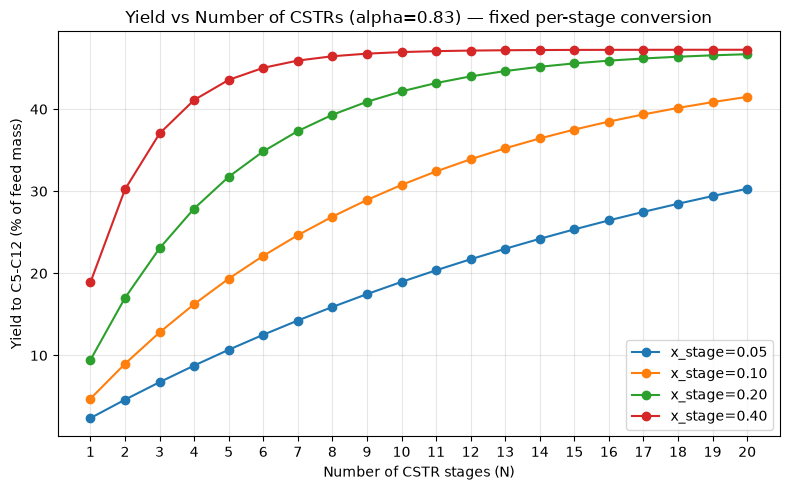


Required per-stage conversions to reach overall X=0.8:
 N= 1: x_stage_required = 0.8000 (yield to C5-C12 = 37.79%)
 N= 2: x_stage_required = 0.5528 (yield to C5-C12 = 37.79%)
 N= 3: x_stage_required = 0.4152 (yield to C5-C12 = 37.79%)
 N= 5: x_stage_required = 0.2752 (yield to C5-C12 = 37.79%)
 N=10: x_stage_required = 0.1487 (yield to C5-C12 = 37.79%)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------
# Parameters
# -----------------------
alpha = 0.83
n_max = 48
n_values = np.arange(1, n_max + 1)

# choose product range for yield (example: C5-C12)
n_min, n_max_range = 5, 12

# compute w_n mass fractions (n=1..48)
def wn(alpha, n):
    return n * (alpha ** (n - 1)) * (1 - alpha) ** 2

w = np.array([wn(alpha, n) for n in n_values])
f_desired = w[(n_values >= n_min) & (n_values <= n_max_range)].sum()

print(f"alpha = {alpha}, fraction in C{n_min}-C{n_max_range} = {f_desired:.6f}")

# -----------------------
# Interpretation A:
# per-stage conversion fraction x_stage (same for each CSTR)
# overall conversion after N identical stages: X_N = 1 - (1 - x_stage)^N
# -----------------------
x_stage_list = [0.05, 0.10, 0.20, 0.40]   # example per-stage conversion fractions

N_max = 20
N_vals = np.arange(1, N_max + 1)

plt.figure(figsize=(8,5))
for x_stage in x_stage_list:
    X_N = 1.0 - (1.0 - x_stage)**N_vals
    yield_percent = X_N * f_desired * 100.0
    plt.plot(N_vals, yield_percent, marker='o', label=f"x_stage={x_stage:.2f}")

plt.xlabel("Number of CSTR stages (N)")
plt.ylabel(f"Yield to C{n_min}-C{n_max_range} (% of feed mass)")
plt.title(f"Yield vs Number of CSTRs (alpha={alpha}) — fixed per-stage conversion")
plt.grid(alpha=0.3)
plt.xticks(N_vals)
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------
# Helpful utility:
# Given a desired overall conversion X_target and number of stages N,
# required per-stage conversion is x_stage_req = 1 - (1 - X_target)^(1/N)
# -----------------------
def required_per_stage_conversion(X_target, N):
    return 1.0 - (1.0 - X_target)**(1.0 / N)

# Example: want overall conversion 0.8
X_target = 0.8
print("\nRequired per-stage conversions to reach overall X=0.8:")
for N in [1,2,3,5,10]:
    x_req = required_per_stage_conversion(X_target, N)
    print(f" N={N:2d}: x_stage_required = {x_req:.4f} (yield to C{n_min}-C{n_max_range} = {X_target*f_desired*100:.2f}%)")



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

X = np.linspace(0, 1, 101)  # conversion from 0 to 1

# methane fraction: n=1
w_ch4 = (1 - alpha_values) ** 2

# methane yield vs conversion
yield_ch4 = X * w_ch4
yield_ch4_percent = 100 * yield_ch4

plt.figure(figsize=(8, 5))
plt.plot(X, yield_ch4_percent, color='tab:blue', linewidth=2)
plt.xlabel("Conversion X")
plt.ylabel("CH4 yield (% of feed mass)")
plt.title(f"CH4 Yield vs Conversion")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"alpha = {alpha_values}")
print(f"w_CH4 = {w_ch4:.6f}")
print(f"CH4 yield formula = {w_ch4:.6f} * X")
print(f"CH4 yield at X=0.8 = {100*w_ch4*0.8:.3f}%")

NameError: name 'alpha_values' is not defined